In [1]:

import usf

import os
usf_folders = [#'/home/matt/geophysics_data/TEM/sTEM_data/2025_0227/USF_Files_dawa river/',
               #'/home/matt/geophysics_data/TEM/sTEM_data/2025_0226/USF_Files_Dawa River Channel/',
            #    'E:/sTEM_data/2025_0302/USF_Files_dawa river 3/',
                #'C:/Users/au646858/Downloads/2025_0622_profiler_sTEM53/USF_Files_profile_day_4_DD_Boren_Aliy_river/',
                'C:/Users/au646858/Downloads/USF_Files_dawa river/'
            #    '/home/matt/geophysics_data/TEM/sTEM_data/2025_0302/USF_Files_dawa river 3/'
               ]

sweeps = []
for usf_folder in usf_folders:
    usf_files = [usf_folder+f for f in os.listdir(usf_folder) if f.endswith('.usf')]
    for usf_file in usf_files:        
        sweeps += usf.Sweep.from_usf(usf_file, combine=False)

In [3]:
swp = sweeps[0]

In [5]:
swp.time

array([1.09820e-05, 1.34004e-05, 1.63515e-05, 1.99524e-05, 2.43463e-05,
       2.97078e-05])

In [53]:
from anemone.forwards import Forward
from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
from usf import Sweep

def sweep2fwr(sweeps, fwr=Forward):
    points = set(swp.points for swp in sweeps)
    forwards = []
    for pnts in points:
        swp = next(swp for swp in sweeps if swp.points == pnts)
        tx = Loop.square(swp.loop_size[0])
        rx = Receiver(x=swp.coil_location[0], y=swp.coil_location[1])
        wv = Waveform(swp.tx_ramp_time, -swp.tx_ramp)
        filter_chain = []
        for f_cut, order in swp.low_pass[::2], swp.low_pass[1::2]:
            filter_chain.append(ButterworthFilter(f_cut))
        fc = FilterChain(filter_chain)
        time = swp.time
        forwards.append(fwr(tx, rx, time, wv, fc, tolerance=1e-6))
    return forwards

In [54]:
fwrs = sweep2fwr(sweeps)
fwrs[0].source = fwrs[1].source
fwrs[0].receiver = fwrs[1].receiver
fwrs[0].filterfunc = fwrs[1].filterfunc

In [55]:
dmfwr = fwrs[0]+fwrs[1]

In [56]:
import torch
rho   = torch.ones(3)*40.
thick = torch.ones(2)*30
dbdt  = dmfwr(rho, thick)

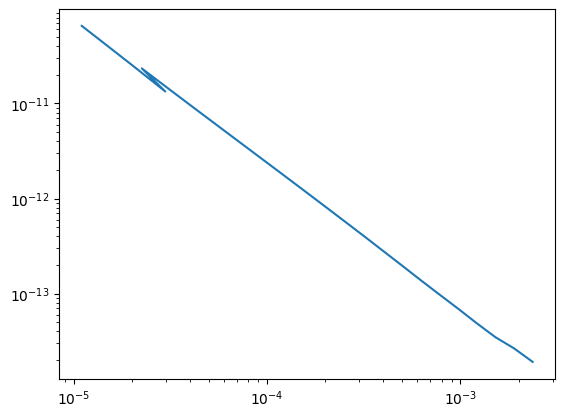

In [57]:
import matplotlib.pyplot as plt
plt.figure()
plt.loglog(dmfwr.times, dbdt)